CNN TRAINING ON MNIST - IMPLEMENTATION DIRECTLY TROUGH PYTORCH

1. IMPORTATION

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps, ImageChops
from scipy import ndimage

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from sklearn.metrics import accuracy_score, f1_score, ConfusionMatrixDisplay

torch.manual_seed(0)
np.random.seed(0)
device = "cpu"

2. DATASET

In [7]:
# Standard normalization of MNIST
MEAN, STD = 0.1307, 0.3081
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((MEAN,), (STD,)),
])

train_set = datasets.MNIST("data", train=True, download=True, transform=transform)
test_set = datasets.MNIST("data", train=False, download=True, transform=transform)
train_loader = DataLoader(train_set, batch_size=64, shuffle=True)
test_loader = DataLoader(test_set, batch_size=1000)
print(f"Train: {len(train_set)}   Test: {len(test_set)}")

Train: 60000   Test: 10000


3. CNN MODEL

In [8]:
from model import CNN

4. TRAINING, EVALUATION AND TEST

In [9]:
model = CNN().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

for epoch in range(5):
    model.train()
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        loss = F.cross_entropy(model(images), labels)
        loss.backward()
        optimizer.step()

    model.eval()
    correct = 0
    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            correct += (model(images).argmax(1) == labels).sum().item()
    print(f"Epoch {epoch + 1} - précision test : {correct / len(test_set):.4f}")

torch.save(model.state_dict(), "mnist_cnn.pt")

Epoch 1 - précision test : 0.9809
Epoch 2 - précision test : 0.9881
Epoch 3 - précision test : 0.9901
Epoch 4 - précision test : 0.9915
Epoch 5 - précision test : 0.9915


5. RESULTS

PyTorch CNN   accuracy: 0.9915   macro-F1: 0.9915


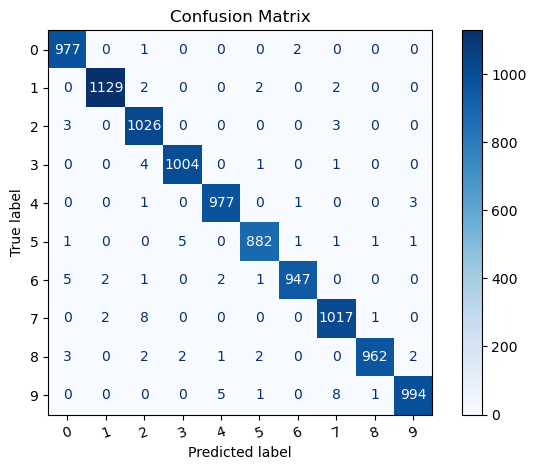

In [10]:
model.eval()
all_preds, all_labels = [], []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        all_preds.append(model(images).argmax(dim=1).cpu())
        all_labels.append(labels)

nn_preds = torch.cat(all_preds).numpy()
y_test = torch.cat(all_labels).numpy()

nn_acc = accuracy_score(y_test, nn_preds)
nn_f1 = f1_score(y_test, nn_preds, average="macro")
print(f"PyTorch CNN   accuracy: {nn_acc:.4f}   macro-F1: {nn_f1:.4f}")

class_names = [str(i) for i in range(10)]
ConfusionMatrixDisplay.from_predictions(y_test, nn_preds, display_labels=class_names,
                                        cmap="Blues", xticks_rotation=20)
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

In conclusion to this basic project, we can see that our model is not perfect, indeed the most common mistakes that the model does are 6 predicted as 0, 7 predicted as 2 and 9 predicted as 4 and 7. Theses errors can come from many things, the dataset itself, if we were to print an image, we would see that some training data is particularly difficult to analyse for a model, moreover, whith more epochs or more layers, we could probably improve our accuracy to 99.5% or even more.